In [ ]:
pip install -q docling

In [ ]:
from docling.document_converter import DocumentConverter
source = "/content/research-paper"
converter = DocumentConverter()
doc = converter.convert(source).document

[INFO] 2026-06-21 21:33:04,850 [RapidOCR] base.py:22: Using engine_name: onnxruntime
[INFO] 2026-06-21 21:33:04,927 [RapidOCR] download_file.py:60: File exists and is valid: /usr/local/lib/python3.12/dist-packages/rapidocr/models/ch_PP-OCRv4_det_mobile.onnx
[INFO] 2026-06-21 21:33:04,929 [RapidOCR] main.py:65: Using /usr/local/lib/python3.12/dist-packages/rapidocr/models/ch_PP-OCRv4_det_mobile.onnx
[INFO] 2026-06-21 21:33:05,203 [RapidOCR] base.py:22: Using engine_name: onnxruntime
[INFO] 2026-06-21 21:33:05,218 [RapidOCR] download_file.py:60: File exists and is valid: /usr/local/lib/python3.12/dist-packages/rapidocr/models/ch_ppocr_mobile_v2.0_cls_mobile.onnx
[INFO] 2026-06-21 21:33:05,225 [RapidOCR] main.py:65: Using /usr/local/lib/python3.12/dist-packages/rapidocr/models/ch_ppocr_mobile_v2.0_cls_mobile.onnx
[INFO] 2026-06-21 21:33:05,351 [RapidOCR] base.py:22: Using engine_name: onnxruntime
[INFO] 2026-06-21 21:33:05,531 [RapidOCR] download_file.py:60: File exists and is valid: /usr

Loading weights:   0%|          | 0/770 [00:00<?, ?it/s]

In [ ]:
import json
import hashlib
from pathlib import Path

from docling_core.transforms.chunker import HierarchicalChunker

# Create output directory
output_dir = Path("output")
output_dir.mkdir(exist_ok=True)

# Chunk document
chunker = HierarchicalChunker()
chunks = [chunk.text for chunk in chunker.chunk(doc)]

# Create JSON structure
chunk_json = {}

for chunk in chunks:
    chunk_hash = hashlib.sha256(
        chunk.encode("utf-8")
    ).hexdigest()

    chunk_json[chunk_hash] = chunk

# Save JSON
json_path = output_dir / "chunks.json"

with open(json_path, "w", encoding="utf-8") as f:
    json.dump(
        chunk_json,
        f,
        ensure_ascii=False,
        indent=2
    )

print(f"Saved {len(chunks)} chunks to {json_path}")

Saved 122 chunks to output/chunks.json


In [ ]:
pip install -q PyMuPDF ultralytics

In [ ]:
import os
import json
import fitz
from PIL import Image
from ultralytics import YOLO

# ─── CONFIG ───────────────────────────────────────────────
INPUT_FILE    = "/content/research-paper"
OUTPUT_DIR    = "output/images"
JSON_FILE     = "output/image_text.json"
MODEL_PATH    = "/content/yolov8s-doclaynet.pt"
DPI           = 200
CONFIDENCE    = 0.5
VICINITY      = 50    # PDF units — how far "nearby" means
# ──────────────────────────────────────────────────────────

FIGURE_LABELS = {"picture", "figure"}

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs("output", exist_ok=True)

model = YOLO(MODEL_PATH)

doc   = fitz.open(INPUT_FILE)
zoom  = DPI / 72
mat   = fitz.Matrix(zoom, zoom)
total = 0

result_json = {}  # { image_path: nearby_text }

for page_num in range(len(doc)):
    page = doc[page_num]
    pix  = page.get_pixmap(matrix=mat)
    page_image = Image.frombytes("RGB", [pix.width, pix.height], pix.samples)

    results = model(page_image, conf=CONFIDENCE)[0]

    fig_count = 0
    for box, cls, conf in zip(results.boxes.xyxy, results.boxes.cls, results.boxes.conf):
        label = model.names[int(cls)].lower()
        if label not in FIGURE_LABELS:
            continue

        # ── Save image ──────────────────────────────────────
        x1, y1, x2, y2 = [int(c) for c in box]
        cropped  = page_image.crop((x1, y1, x2, y2))
        filename = f"page{page_num + 1}_figure{fig_count + 1}.png"
        img_path = os.path.join(OUTPUT_DIR, filename)
        cropped.save(img_path)

        # ── Get nearby text ──────────────────────────────────
        # Convert pixel bbox back to PDF units for text search
        pdf_x1 = x1 / zoom
        pdf_y1 = y1 / zoom
        pdf_x2 = x2 / zoom
        pdf_y2 = y2 / zoom

        # Expand the box by VICINITY to capture surrounding text
        search_rect = fitz.Rect(
            pdf_x1 - VICINITY,
            pdf_y1 - VICINITY,
            pdf_x2 + VICINITY,
            pdf_y2 + VICINITY
        )

        # Extract text only within that expanded region
        nearby_text = page.get_text("text", clip=search_rect).strip()

        # ── Store in JSON ────────────────────────────────────
        result_json[img_path] = nearby_text

        print(f"  Saved : {filename}  (conf: {conf:.2f})")
        print(f"  Text  : {nearby_text[:80]}{'...' if len(nearby_text) > 80 else ''}")

        fig_count += 1
        total += 1

    print(f"Page {page_num + 1}: {fig_count} figure(s) found\n")

doc.close()

# ── Write JSON ───────────────────────────────────────────
with open(JSON_FILE, "w", encoding="utf-8") as f:
    json.dump(result_json, f, indent=4, ensure_ascii=False)

print(f"[✓] Done! {total} images saved to : {OUTPUT_DIR}/")
print(f"[✓] JSON saved to                 : {JSON_FILE}")


0: 1024x800 1 Page-footer, 5 Section-headers, 15 Texts, 1 Title, 4379.9ms
Speed: 12.8ms preprocess, 4379.9ms inference, 2.5ms postprocess per image at shape (1, 3, 1024, 800)
Page 1: 0 figure(s) found


0: 1024x800 1 List-item, 1 Page-footer, 1 Page-header, 1 Picture, 8 Texts, 3223.5ms
Speed: 20.1ms preprocess, 3223.5ms inference, 1.7ms postprocess per image at shape (1, 3, 1024, 800)
  Saved : page2_figure1.png  (conf: 0.94)
  Text  : MM ’25, October 27–31, 2025, Dublin, Ireland
Figure 1: Comparison of (𝑎) single-...
Page 2: 1 figure(s) found


0: 1024x800 1 Formula, 3 List-items, 1 Page-footer, 5 Section-headers, 10 Texts, 2719.5ms
Speed: 15.0ms preprocess, 2719.5ms inference, 1.4ms postprocess per image at shape (1, 3, 1024, 800)
Page 3: 0 figure(s) found


0: 1024x800 1 Page-footer, 1 Page-header, 1 Picture, 1 Section-header, 11 Texts, 2301.9ms
Speed: 11.8ms preprocess, 2301.9ms inference, 2.0ms postprocess per image at shape (1, 3, 1024, 800)
  Saved : page4_figure1.png  (conf: 0

In [ ]:
pip install -q groq

In [ ]:
import os
import json
import hashlib
from groq import Groq

# ─── CONFIG ───────────────────────────────────────────────
INPUT_JSON  = "output/image_text.json"
OUTPUT_JSON = "output/image_descriptions.json"
client = Groq(api_key="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")
# ──────────────────────────────────────────────────────────

def image_to_base64_for_groq(image_path):
    import base64
    with open(image_path, "rb") as f:
        return base64.b64encode(f.read()).decode("utf-8")

def sha256_hash(image_path):
    with open(image_path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()

def generate_description(image_base64, nearby_text):
    prompt = f"""
You are extracting information from a PDF.
Nearby text:
{nearby_text}
Task:
Generate a concise, information-dense description of the image.
Use nearby text only when relevant.
Return only the description.
"""
    completion = client.chat.completions.create(
        model="meta-llama/llama-4-scout-17b-16e-instruct",
        messages=[
            {
                "role": "user",
                "content": [
                    {"type": "text", "text": prompt},
                    {
                        "type": "image_url",
                        "image_url": {"url": f"data:image/jpeg;base64,{image_base64}"},
                    },
                ],
            }
        ],
        temperature=0.2,
        max_completion_tokens=300,
    )
    return completion.choices[0].message.content

# ─── MAIN ─────────────────────────────────────────────────
with open(INPUT_JSON, "r") as f:
    image_text = json.load(f)

output = {}

for img_path, nearby_text in image_text.items():
    if not os.path.exists(img_path):
        print(f"  Skipping (not found): {img_path}")
        continue

    print(f"Processing: {img_path}")

    b64         = image_to_base64_for_groq(img_path)   # only for API call
    sha         = sha256_hash(img_path)
    description = generate_description(b64, nearby_text)

    output[sha] = [img_path, description]              # path instead of base64
    print(f"  Hash : {sha[:20]}...")
    print(f"  Desc : {description[:80]}...")

with open(OUTPUT_JSON, "w", encoding="utf-8") as f:
    json.dump(output, f, indent=4, ensure_ascii=False)

print(f"\n[✓] Done! Saved to: {OUTPUT_JSON}")

Processing: output/images/page2_figure1.png
  Hash : 8ceaf231aa453c62f7c7...
  Desc : The image presents a comparison between two types of RAG (Retrieval-Augmented Ge...
Processing: output/images/page4_figure1.png
  Hash : ff24611adb52c958332e...
  Desc : The image illustrates a multi-agent, multi-modal framework called HM-RAG, which ...
Processing: output/images/page8_figure1.png
  Hash : c75cdee6206330427c4e...
  Desc : A map of the eastern United States with one highlighted colony in dark green, lo...

[✓] Done! Saved to: output/image_descriptions.json


In [ ]:
import json
import numpy as np
from pathlib import Path
from PIL import Image
from sentence_transformers import SentenceTransformer, util

# ─── CONFIG ───────────────────────────────────────────────
output_dir        = Path("output")
chunks_path       = output_dir / "chunks.json"
images_path       = output_dir / "image_descriptions.json"
embeddings_path   = output_dir / "embeddings.json"

SIMILARITY_THRESHOLD = 0.6   # Lower for CLIP cross-modal similarity

# ─── LOAD DATA ────────────────────────────────────────────
with open(chunks_path, "r", encoding="utf-8") as f:
    chunks_json = json.load(f)

with open(images_path, "r", encoding="utf-8") as f:
    images_json = json.load(f)

# ─── LOAD MODELS ──────────────────────────────────────────
text_model  = SentenceTransformer("clip-ViT-B-32")          # CLIP text encoder
image_model = SentenceTransformer("clip-ViT-B-32")          # CLIP image encoder

# ─── PREPARE DATA ─────────────────────────────────────────
chunk_ids   = list(chunks_json.keys())
chunk_texts = list(chunks_json.values())

image_ids        = list(images_json.keys())
image_paths      = [images_json[iid][0] for iid in image_ids]
image_descs      = [images_json[iid][1] for iid in image_ids]

# ─── ENCODE TEXT CHUNKS (CLIP text encoder) ───────────────
chunk_embeddings = text_model.encode(chunk_texts, convert_to_tensor=True, show_progress_bar=True)

# ─── ENCODE IMAGE DESCRIPTIONS (for cosine similarity pairing only) ───
desc_embeddings  = text_model.encode(image_descs,  convert_to_tensor=True, show_progress_bar=True)

# ─── ENCODE IMAGES (CLIP image encoder) ───────────────────
raw_image_embeddings = []
valid_image_ids      = []
valid_image_paths    = []

for iid, img_path in zip(image_ids, image_paths):
    try:
        img = Image.open(img_path).convert("RGB")
        emb = image_model.encode(img, convert_to_tensor=True)
        raw_image_embeddings.append(emb)
        valid_image_ids.append(iid)
        valid_image_paths.append(img_path)
    except Exception as e:
        print(f"Skipping {img_path}: {e}")

# ─── OLS LINEAR MAPPING (train on chunk_text ↔ image_desc pairs) ──────
# Using paired (text_desc_embedding, raw_image_embedding) to learn L_M
# such that L_M @ image_vec ≈ text_vec  (aligns image space → text space)

X = np.array([e.cpu().numpy() for e in raw_image_embeddings])   # image vecs  (n, d)
Y = np.array([desc_embeddings[image_ids.index(iid)].cpu().numpy() for iid in valid_image_ids])  # text vecs (n, d)

# Closed-form OLS: L_M = (X^T X)^{-1} X^T Y
L_M = np.linalg.lstsq(X, Y, rcond=None)[0]   # shape (d, d)
print(f"OLS mapping computed: {L_M.shape}")

# ─── APPLY OLS → ALIGNED IMAGE EMBEDDINGS ─────────────────
aligned_image_embeddings = {
    iid: X[i] @ L_M
    for i, iid in enumerate(valid_image_ids)
}

# ─── FIND BEST MATCHING CHUNK FOR EACH IMAGE ──────────────
# Each image → find chunk with maximum cosine similarity
embeddings_dict = {}

# Store standalone text chunk embeddings first
for i, cid in enumerate(chunk_ids):
    embeddings_dict[cid] = {
        "type"     : "text",
        "embedding": chunk_embeddings[i].cpu().numpy().tolist()
    }

used_chunk_ids = set()

for j, iid in enumerate(valid_image_ids):
    img_desc_emb = desc_embeddings[image_ids.index(iid)]

    # Cosine similarity between this image description and ALL chunks
    sims = util.cos_sim(img_desc_emb, chunk_embeddings)[0]  # (num_chunks,)

    best_idx  = sims.argmax().item()
    best_sim  = sims[best_idx].item()
    best_cid  = chunk_ids[best_idx]

    if best_sim >= SIMILARITY_THRESHOLD:
        # Concatenate: aligned_image_vec + text_chunk_vec
        text_vec  = chunk_embeddings[best_idx].cpu().numpy()          # (d,)
        img_vec   = aligned_image_embeddings[iid]                      # (d,)
        fused_vec = np.concatenate([text_vec, img_vec], axis=0)        # (2d,)

        pair_key = f"({best_cid},{iid})"
        embeddings_dict[pair_key] = {
            "type"      : "text+image",
            "chunk_id"  : best_cid,
            "image_id"  : iid,
            "similarity": round(best_sim, 4),
            "embedding" : fused_vec.tolist()
        }

        used_chunk_ids.add(best_cid)
        print(f"Paired chunk {best_cid[:12]}... ↔ image {iid[:12]}... (sim={best_sim:.3f})")
    else:
        # No good match — store image embedding standalone (aligned)
        embeddings_dict[iid] = {
            "type"     : "image",
            "embedding": aligned_image_embeddings[iid].tolist()
        }
        print(f"No match for image {iid[:12]}... (best sim={best_sim:.3f}) — stored standalone")

# ─── SAVE ─────────────────────────────────────────────────
with open(embeddings_path, "w", encoding="utf-8") as f:
    json.dump(embeddings_dict, f, ensure_ascii=False, indent=2)

print(f"\n[✓] Saved {len(embeddings_dict)} embeddings to {embeddings_path}")
print(f"    Text-only     : {sum(1 for v in embeddings_dict.values() if v['type']=='text')}")
print(f"    Image-only    : {sum(1 for v in embeddings_dict.values() if v['type']=='image')}")
print(f"    Text + Image  : {sum(1 for v in embeddings_dict.values() if v['type']=='text+image')}")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Batches:   0%|          | 0/4 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

OLS mapping computed: (512, 512)
Paired chunk d5021be4b51e... ↔ image 8ceaf231aa45... (sim=0.891)
Paired chunk 78213b7f0c56... ↔ image ff24611adb52... (sim=0.948)
No match for image c75cdee62063... (best sim=0.424) — stored standalone

[✓] Saved 112 embeddings to output/embeddings.json
    Text-only     : 109
    Image-only    : 1
    Text + Image  : 2


In [ ]:
np.save("output/ols_mapping.npy", L_M)

In [ ]:
pip install -q chromadb sentence-transformers

In [ ]:
# ─── RESET COLLECTIONS (run when switching documents) ─────
try:
    client.delete_collection("text_chunks")
    client.delete_collection("fused_chunks")
    print("[✓] Old collections deleted")
except:
    print("[–] No existing collections to delete")

[–] No existing collections to delete


In [ ]:
import json
import numpy as np
from pathlib import Path
import chromadb
import shutil # Import shutil for rmtree

# ─── PATHS ────────────────────────────────────────────────
output_dir      = Path("output")
embeddings_path = output_dir / "embeddings.json"
chroma_path     = Path("chroma_db1") # Use Path object for consistency

# Ensure the chroma_path directory exists and is clean for a new run
# This is a common workaround for "readonly database" or "no such table" errors in notebooks
if chroma_path.exists():
    print(f"[!] Removing existing ChromaDB at {chroma_path}")
    shutil.rmtree(chroma_path) # Remove the directory and all its contents
chroma_path.mkdir(parents=True, exist_ok=True) # Recreate the directory


# ─── LOAD EMBEDDINGS DICT ─────────────────────────────────
with open(embeddings_path, "r", encoding="utf-8") as f:
    embeddings_dict = json.load(f)

# ─── CHROMADB SETUP ───────────────────────────────────────
client = chromadb.PersistentClient(path=str(chroma_path)) # Convert Path to string for chromadb

# Two separate collections — text (512d) and fused (1024d)
# ChromaDB requires all vectors in a collection to have same dimension
text_collection  = client.get_or_create_collection(name="text_chunks")
fused_collection = client.get_or_create_collection(name="fused_chunks")

# ─── PREPARE RECORDS ──────────────────────────────────────
text_ids   , text_embeddings   , text_metadatas    = [], [], []
fused_ids  , fused_embeddings  , fused_metadatas   = [], [], []

for record_id, record in embeddings_dict.items():
    emb  = record["embedding"]
    rtype = record["type"]

    if rtype == "text":
        text_ids.append(record_id)
        text_embeddings.append(emb)
        text_metadatas.append({
            "type"     : "text",
            "chunk_id" : record_id
        })

    elif rtype == "image":
        # Standalone image — store in text collection (OLS-aligned, same 512d)
        text_ids.append(record_id)
        text_embeddings.append(emb)
        text_metadatas.append({
            "type"    : "image",
            "image_id": record_id
        })

    elif rtype == "text+image":
        fused_ids.append(record_id)
        fused_embeddings.append(emb)
        fused_metadatas.append({
            "type"      : "text+image",
            "chunk_id"  : record["chunk_id"],
            "image_id"  : record["image_id"],
            "similarity": record["similarity"]
        })

# ─── STORE INTO CHROMADB ──────────────────────────────────
if text_ids:
    text_collection.add(
        ids        = text_ids,
        embeddings = text_embeddings,
        metadatas  = text_metadatas
    )
    print(f"[✓] Stored {len(text_ids)} records in 'text_chunks' collection")

if fused_ids:
    fused_collection.add(
        ids        = fused_ids,
        embeddings = fused_embeddings,
        metadatas  = fused_metadatas
    )
    print(f"[✓] Stored {len(fused_ids)} records in 'fused_chunks' collection")

# ─── VERIFY ───────────────────────────────────────────────
print(f"\n── Collection Summary ──────────────────────────")
print(f"  text_chunks  : {text_collection.count()} records  (dim=512)")
print(f"  fused_chunks : {fused_collection.count()} records  (dim=1024)")
print(f"────────────────────────────────────────────────")

[✓] Stored 110 records in 'text_chunks' collection
[✓] Stored 2 records in 'fused_chunks' collection

── Collection Summary ──────────────────────────
  text_chunks  : 110 records  (dim=512)
  fused_chunks : 2 records  (dim=1024)
────────────────────────────────────────────────


In [ ]:
import json
import numpy as np
from pathlib import Path
from PIL import Image
from sentence_transformers import SentenceTransformer
import chromadb

# ─── PATHS ────────────────────────────────────────────────
output_dir      = Path("output")
embeddings_path = output_dir / "embeddings.json"
chroma_path     = Path("/content/chroma_db1") # Changed to store in /content/

# ─── LOAD OLS MAPPING ─────────────────────────────────────
# We need L_M to align query image embedding (if image query)
# L_M was computed in previous cell — recompute or save/load it
# For now: load embeddings to recompute L_M
with open(embeddings_path, "r", encoding="utf-8") as f:
    embeddings_dict = json.load(f)

# ─── LOAD MODELS ──────────────────────────────────────────
text_model  = SentenceTransformer("clip-ViT-B-32")
image_model = SentenceTransformer("clip-ViT-B-32")

# ─── CHROMADB SETUP ───────────────────────────────────────
client           = chromadb.PersistentClient(path=str(chroma_path))
text_collection  = client.get_collection("text_chunks")
fused_collection = client.get_collection("fused_chunks")

# ─── LOAD OLS MATRIX ──────────────────────────────────────
# Save L_M in previous cell using np.save("output/ols_mapping.npy", L_M)
# Load it here
ols_path = output_dir / "ols_mapping.npy"
L_M      = np.load(ols_path)

# ─── QUERY ENCODER ────────────────────────────────────────
def encode_query(query_text=None, query_image_path=None):
    """
    Returns:
        query_vec_512  : for text_collection  search
        query_vec_1024 : for fused_collection search
    """
    if query_text and query_image_path:
        # Text + Image query
        text_vec  = text_model.encode(query_text, convert_to_numpy=True)          # (512,)
        img       = Image.open(query_image_path).convert("RGB")
        img_vec   = image_model.encode(img, convert_to_numpy=True)                # (512,)
        img_vec   = img_vec @ L_M                                                 # OLS align
        query_512 = (text_vec + img_vec) / 2                                      # average
        query_1024 = np.concatenate([text_vec, img_vec], axis=0)                  # (1024,)

    elif query_image_path:
        # Image-only query
        img       = Image.open(query_image_path).convert("RGB")
        img_vec   = image_model.encode(img, convert_to_numpy=True)                # (512,)
        img_vec   = img_vec @ L_M                                                 # OLS align
        query_512  = img_vec                                                       # (512,)
        query_1024 = np.concatenate([img_vec, img_vec], axis=0)                   # (1024,)

    else:
        # Text-only query (default)
        text_vec   = text_model.encode(query_text, convert_to_numpy=True)         # (512,)
        query_512  = text_vec                                                      # (512,)
        query_1024 = np.concatenate([text_vec, text_vec], axis=0)                 # (1024,)

    return query_512.tolist(), query_1024.tolist()


# ─── RECIPROCAL RANK FUSION ───────────────────────────────
def reciprocal_rank_fusion(results_a, results_b, k=60, top_n=10):
    """
    results_a, results_b : ChromaDB query results dicts
    Fuses rankings from two collections using RRF.
    Returns top_n fused results.
    """
    scores = {}
    docs   = {}
    metas  = {}

    for rank, (doc_id, doc, meta) in enumerate(zip(
        results_a["ids"][0],
        results_a["documents"][0] if results_a["documents"] else [""] * len(results_a["ids"][0]),
        results_a["metadatas"][0]
    )):
        scores[doc_id] = scores.get(doc_id, 0) + 1 / (k + rank + 1)
        docs[doc_id]   = doc
        metas[doc_id]  = meta

    for rank, (doc_id, doc, meta) in enumerate(zip(
        results_b["ids"][0],
        results_b["documents"][0] if results_b["documents"] else [""] * len(results_b["ids"][0]),
        results_b["metadatas"][0]
    )):
        scores[doc_id] = scores.get(doc_id, 0) + 1 / (k + rank + 1)
        docs[doc_id]   = doc
        metas[doc_id]  = meta

    # Sort by fused score descending
    ranked = sorted(scores.items(), key=lambda x: x[1], reverse=True)[:top_n]

    return [
        {
            "id"       : doc_id,
            "rrf_score": round(score, 6),
            "metadata" : metas[doc_id]
        }
        for doc_id, score in ranked
    ]


# ─── MAIN RETRIEVAL FUNCTION ──────────────────────────────
def retrieve(query_text=None, query_image_path=None, top_k=10):

    query_512, query_1024 = encode_query(query_text, query_image_path)

    # ── Search text_collection (512d) ─────────────────────
    text_results = text_collection.query(
        query_embeddings = [query_512],
        n_results        = top_k,
        include          = ["metadatas", "documents"]
    )

    # ── Search fused_collection (1024d) ───────────────────
    fused_results = fused_collection.query(
        query_embeddings = [query_1024],
        n_results        = top_k,
        include          = ["metadatas", "documents"]
    )

    # ── Late Fusion via RRF ───────────────────────────────
    fused_ranked = reciprocal_rank_fusion(text_results, fused_results, top_n=top_k)

    return fused_ranked


# ─── GET QUERY FROM USER ──────────────────────────────────
print("─── Multimodal RAG Retrieval ───────────────────")
query_text       = input("Enter your text query (or press Enter to skip): ").strip() or None
query_image_path = input("Enter image path (or press Enter to skip)     : ").strip() or None

if not query_text and not query_image_path:
    print("Please provide at least a text or image query.")
else:
    results = retrieve(query_text=query_text, query_image_path=query_image_path, top_k=10)

    print(f"\n─── Top {len(results)} Retrieved Documents ─────────────────")
    for i, res in enumerate(results, 1):
        print(f"\n[{i}] ID        : {res['id']}")
        print(f"    RRF Score : {res['rrf_score']}")
        print(f"    Type      : {res['metadata'].get('type')}")
        if res['metadata'].get('chunk_id'):
            print(f"    Chunk ID  : {res['metadata']['chunk_id'][:20]}...")
        if res['metadata'].get('image_id'):
            print(f"    Image ID  : {res['metadata']['image_id'][:20]}...")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

─── Multimodal RAG Retrieval ───────────────────
Enter your text query (or press Enter to skip): Give me Overview of HM-RAG. A multi-agent multi-modal framework
Enter image path (or press Enter to skip)     : 

─── Top 10 Retrieved Documents ─────────────────

[1] ID        : 8867ec3055abd0d3d6ecf12bb9bdaa103dc2f308405e6715f02ec9759c0fd690
    RRF Score : 0.016393
    Type      : text
    Chunk ID  : 8867ec3055abd0d3d6ec...

[2] ID        : (d5021be4b51ed32fbffa5cac926b991c13fa1cd5e352392ea3aa38fe7996504b,8ceaf231aa453c62f7c7b8cace0602d7782a8404e0f2f246980f4ac6c182ca29)
    RRF Score : 0.016393
    Type      : text+image
    Chunk ID  : d5021be4b51ed32fbffa...
    Image ID  : 8ceaf231aa453c62f7c7...

[3] ID        : 107a4713fa2b067f078e722a24e9c569b35f2ddf7bfd18f2e7601217c6cff019
    RRF Score : 0.016129
    Type      : text
    Chunk ID  : 107a4713fa2b067f078e...

[4] ID        : (78213b7f0c56872f5ea975babb83da4735bb0601655b34ddfba082b1e217efa2,ff24611adb52c958332e1bc556362ff5c8128f7e

In [ ]:
from sentence_transformers import CrossEncoder
from pathlib import Path
import json

# ─── LOAD RAW CONTENT FOR RERANKING ──────────────────────
# Reranker needs actual text content, not just IDs
output_dir  = Path("output")

with open(output_dir / "chunks.json", "r") as f:
    chunks_json = json.load(f)

with open(output_dir / "image_descriptions.json", "r") as f:
    images_json = json.load(f)

# ─── RESOLVE TEXT CONTENT FROM RETRIEVED IDS ─────────────
def resolve_content(record):
    """Get actual text content from a retrieved record."""
    rtype    = record["metadata"].get("type")
    chunk_id = record["metadata"].get("chunk_id", "")
    image_id = record["metadata"].get("image_id", "")

    if rtype == "text":
        return chunks_json.get(record["id"], "")

    elif rtype == "image":
        return images_json.get(record["id"], ["", ""])[1]   # description

    elif rtype == "text+image":
        chunk_text = chunks_json.get(chunk_id, "")
        image_desc = images_json.get(image_id, ["", ""])[1]
        return chunk_text + "\n\n" + image_desc

    return ""

# ─── LOAD RERANKER ────────────────────────────────────────
reranker = CrossEncoder("BAAI/bge-reranker-base")

# ─── BUILD QUERY STRING ───────────────────────────────────
query_for_reranker = query_text or ""   # CrossEncoder needs text query

# ─── RESOLVE CONTENT FOR ALL 10 RESULTS ──────────────────
resolved = [
    {
        "id"      : res["id"],
        "content" : resolve_content(res),
        "metadata": res["metadata"],
        "rrf_score": res["rrf_score"]
    }
    for res in results
]

# ─── RERANK ───────────────────────────────────────────────
pairs  = [[query_for_reranker, doc["content"]] for doc in resolved]
scores = reranker.predict(pairs)

reranked = sorted(
    zip(resolved, scores),
    key    = lambda x: x[1],
    reverse= True
)[:5]

# ─── DISPLAY TOP 5 ────────────────────────────────────────
print("─── Top 5 Reranked Documents ───────────────────")
for rank, (doc, score) in enumerate(reranked, 1):
    print(f"\n[{rank}] ID         : {doc['id']}")
    print(f"     Type       : {doc['metadata'].get('type')}")
    print(f"     RRF Score  : {doc['rrf_score']}")
    print(f"     Rerank Score: {score:.4f}")
    print(f"     Content    : {doc['content'][:200]}...")

# ─── STORE FOR NEXT CELL (LLM Generation) ─────────────────
top_5_docs = [doc for doc, score in reranked]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

─── Top 5 Reranked Documents ───────────────────

[1] ID         : (78213b7f0c56872f5ea975babb83da4735bb0601655b34ddfba082b1e217efa2,ff24611adb52c958332e1bc556362ff5c8128f7ee3d0a04ffa1bc1eaa8982f3f)
     Type       : text+image
     RRF Score  : 0.016129
     Rerank Score: 0.9995
     Content    : Figure 2: Overview of HM-RAG. A multi-agent multi-modal framework operates in three stages: First, the Decomposition Agent uses an LLM to rewrite and decompose the question into several sub-queries. S...

[2] ID         : bc2862ae5d6a3c4f9a80dce7d35d6ecd086d64ad8ce23857cd558545fecd5ebd
     Type       : text
     RRF Score  : 0.015625
     Rerank Score: 0.9964
     Content    : We introduce HM-RAG, a novel framework tackling complex challenges in RAG systems. As depicted in Figure 2, HM-RAG features an innovative multi-agent, multimodal architecture with specialized agents f...

[3] ID         : fbcb6d80554ccb31d026c925f6e22c1c060f7470bfbd61bc624ac38e18402482
     Type       : text
     RRF S

In [ ]:
pip install -q langchain-groq

In [ ]:
from langchain_groq import ChatGroq
from langchain_core.messages import HumanMessage
import base64
import json
from pathlib import Path

# ─── LOAD RAW CONTENT ─────────────────────────────────────
output_dir = Path("output")

with open(output_dir / "chunks.json", "r") as f:
    chunks_json = json.load(f)

with open(output_dir / "image_descriptions.json", "r") as f:
    images_json = json.load(f)

# ─── LLM SETUP ────────────────────────────────────────────
llm = ChatGroq(
    model       = "meta-llama/llama-4-scout-17b-16e-instruct",
    api_key     = "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",
    temperature = 0.2,
    max_tokens  = 700
)

# ─── HELPER ───────────────────────────────────────────────
def path_to_base64(image_path):
    with open(image_path, "rb") as f:
        return base64.b64encode(f.read()).decode("utf-8")

# ─── RESOLVE ACTUAL CONTENT FROM TOP 5 IDS ────────────────
text_context   = ""
images_for_llm = []

for rank, doc in enumerate(top_5_docs, 1):
    rtype    = doc["metadata"].get("type")
    chunk_id = doc["metadata"].get("chunk_id", "")
    image_id = doc["metadata"].get("image_id", "")

    text_context += f"\n\n--- Rank {rank} | Type: {rtype} ---\n"

    if rtype == "text":
        # Fetch actual chunk text from chunks.json
        chunk_text    = chunks_json.get(doc["id"], "")
        text_context += chunk_text

    elif rtype == "image":
        # Fetch image description from images_json
        image_data    = images_json.get(doc["id"], ["", ""])
        text_context += f"Image Description: {image_data[1]}"
        images_for_llm.append({
            "rank"       : rank,
            "image_path" : image_data[0],
            "description": image_data[1]
        })

    elif rtype == "text+image":
        # Fetch both chunk text AND actual image
        chunk_text    = chunks_json.get(chunk_id, "")
        image_data    = images_json.get(image_id, ["", ""])
        text_context += chunk_text
        text_context += f"\nAssociated Image Description: {image_data[1]}"
        images_for_llm.append({
            "rank"       : rank,
            "image_path" : image_data[0],
            "description": image_data[1]
        })

# ─── BUILD MULTIMODAL PROMPT ──────────────────────────────
query = query_text or "Describe the relevant content."

content = [
    {
        "type": "text",
        "text": f"""You are answering a user query using retrieved content from a PDF.
The content includes text chunks and images where relevant.

User Query:
{query}

Retrieved Context (ranked by relevance):
{text_context}

Instructions:
- Answer strictly from the provided context.
- If images are provided refer to them by their rank (e.g. Image from Rank 2).
- If the context is insufficient say so clearly.
- Be concise and precise.
"""
    }
]

# ─── ATTACH ACTUAL IMAGES ─────────────────────────────────
for img_info in images_for_llm:
    try:
        b64 = path_to_base64(img_info["image_path"])
        content.append({
            "type"     : "image_url",
            "image_url": {"url": f"data:image/jpeg;base64,{b64}"}
        })
        content.append({
            "type": "text",
            "text": f"Above image belongs to Rank {img_info['rank']}. Description: {img_info['description']}"
        })
    except FileNotFoundError:
        print(f"Image not found: {img_info['image_path']} — skipping")

# ─── INVOKE LLM ───────────────────────────────────────────
response = llm.invoke([HumanMessage(content=content)])
answer   = response.content

print("─── Generated Answer ───────────────────────────")
print(answer)

─── Generated Answer ───────────────────────────
## Overview of HM-RAG: A Multi-Agent Multi-Modal Framework

HM-RAG is a novel framework designed to tackle complex challenges in Retrieval-Augmented Generation (RAG) systems. It features an innovative multi-agent, multi-modal architecture with specialized agents for information extraction and multi-source retrieval.

### Key Components of HM-RAG

The HM-RAG framework operates in three stages:

1.  **Decomposition Agent**: This agent uses a Large Language Model (LLM) to rewrite and decompose the input question into several sub-queries.
2.  **Multi-Source Retrieval Agent**: This agent retrieves the top-k relevant documents from various sources, including vector-, graph-, and web-based sources as needed.
3.  **Decision Agent**: This agent provides a voting mechanism and refinement process to generate the final answer.

### Architecture and Functionality

The framework's architecture is designed to handle complex queries and diverse data typ

In [ ]:
pip install -q networkx sentence-transformers

In [ ]:
import networkx as nx
from sentence_transformers import SentenceTransformer, util
from PIL import Image
import nltk
nltk.download('punkt_tab')
from nltk.tokenize import sent_tokenize

# ─── MODEL ────────────────────────────────────────────────
model = SentenceTransformer("clip-ViT-B-32")   # CLIP — consistent with pipeline

# ─── EXTRACT RETRIEVED IMAGES FROM TOP 5 ──────────────────
# images_for_llm was built in the LLM cell
# { image_id : [image_path, description] }
retrieved_images = {
    images_json[img["image_id"]] if "image_id" in img else img["image_path"]:
    [img["image_path"], img["description"]]
    for img in images_for_llm
}

# Cleaner: rebuild directly from images_for_llm
retrieved_images = {}
for img_info in images_for_llm:
    img_path = img_info["image_path"]
    desc     = img_info["description"]
    retrieved_images[img_path] = [img_path, desc]

# ─── TOKENIZE ANSWER INTO SENTENCES ───────────────────────
sentences  = sent_tokenize(answer)
image_keys = list(retrieved_images.keys())    # image_path as key
image_descs = [retrieved_images[k][1] for k in image_keys]

print(f"Sentences : {len(sentences)}")
print(f"Images    : {len(image_keys)}")

# ─── ENCODE ───────────────────────────────────────────────
sentence_embeddings = model.encode(sentences,   convert_to_tensor=True)
image_embeddings    = model.encode(image_descs, convert_to_tensor=True)

# ─── BUILD BIPARTITE GRAPH ────────────────────────────────
G = nx.Graph()

for i, sentence in enumerate(sentences):
    for j, img_key in enumerate(image_keys):
        similarity = util.cos_sim(
            sentence_embeddings[i],
            image_embeddings[j]
        ).item()

        if similarity > 0.2:
            G.add_edge(
                f"s_{i}",
                f"img_{j}",
                weight=similarity
            )

# ─── EDMONDS' BLOSSOM ALGORITHM ───────────────────────────
# Max weight matching — each sentence gets at most one image
# Each image gets at most one sentence
matching = nx.algorithms.matching.max_weight_matching(
    G,
    maxcardinality=False    # quality over quantity — only strong matches
)

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Sentences : 16
Images    : 2


In [ ]:
# ─── RESOLVE MATCHING → sentence_id : image_path ──────────
sentence_to_image = {}

for a, b in matching:
    if a.startswith("s_"):
        sentence_idx = int(a.split("_")[1])
        image_idx    = int(b.split("_")[1])
    else:
        sentence_idx = int(b.split("_")[1])
        image_idx    = int(a.split("_")[1])

    sentence_to_image[sentence_idx] = image_keys[image_idx]


─── Multimodal Answer ──────────────────────────

## Overview of HM-RAG: A Multi-Agent Multi-Modal Framework

HM-RAG is a novel framework designed to tackle complex challenges in Retrieval-Augmented Generation (RAG) systems.
It features an innovative multi-agent, multi-modal architecture with specialized agents for information extraction and multi-source retrieval.
### Key Components of HM-RAG

The HM-RAG framework operates in three stages:

1.
**Decomposition Agent**: This agent uses a Large Language Model (LLM) to rewrite and decompose the input question into several sub-queries.
2.
**Multi-Source Retrieval Agent**: This agent retrieves the top-k relevant documents from various sources, including vector-, graph-, and web-based sources as needed.
3.
**Decision Agent**: This agent provides a voting mechanism and refinement process to generate the final answer.
### Architecture and Functionality

The framework's architecture is designed to handle complex queries and diverse data types,

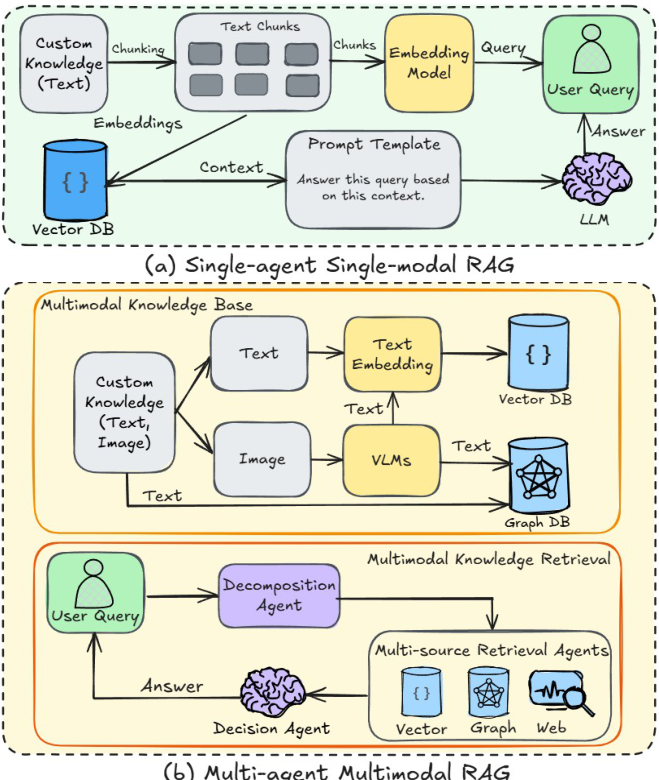

In contrast, HM-RAG involves multiple agents that process multimodal data, making it more advanced in handling complex queries and diverse data types.
### Image Illustration

The HM-RAG framework is illustrated in an image (from Rank 1), which shows the three stages of operation:

*   **Question Decomposition and Rewrite**: The Decomposition Agent uses an LLM to rewrite and decompose the question into sub-queries.

[Image: output/images/page4_figure1.png]
[Caption: The image illustrates a multi-agent, multi-modal framework called HM-RAG, which operates in three st...]



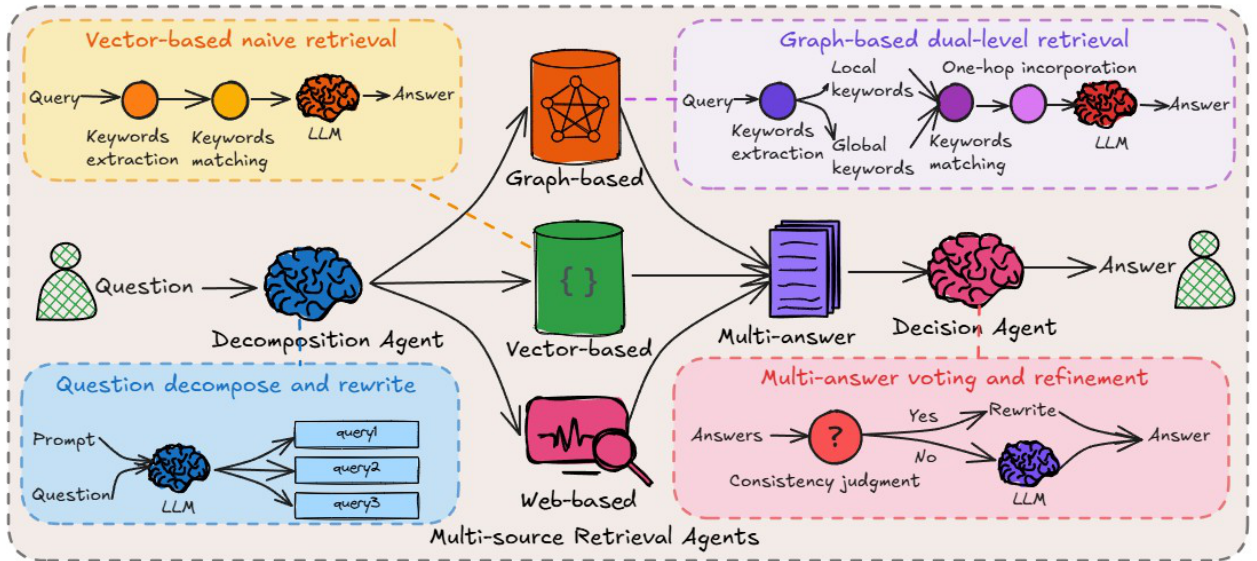

*   **Multi-Source Retrieval Agents**: The Multi-Source Retrieval Agent retrieves relevant documents from various sources.
*   **Multi-Answer Voting and Refinement**: The Decision Agent refines the answers through a voting mechanism.
Overall, HM-RAG presents a cutting-edge approach to RAG systems, offering improved performance in handling complex queries and diverse data types.

────────────────────────────────────────────────
Total sentences         : 16
Images matched          : 2
Sentences without image : 14


In [ ]:
# ─── RENDER MULTIMODAL ANSWER ─────────────────────────────
print("\n─── Multimodal Answer ──────────────────────────\n")

for i, sentence in enumerate(sentences):
    print(sentence)

    if i in sentence_to_image:
        img_path = sentence_to_image[i]
        desc     = retrieved_images[img_path][1]

        print(f"\n[Image: {img_path}]")
        print(f"[Caption: {desc[:100]}...]\n")

        # Display image inline (Colab)
        try:
            from IPython.display import display
            img = Image.open(img_path)
            display(img)
        except Exception as e:
            print(f"Could not display image: {e}")

print("\n────────────────────────────────────────────────")
print(f"Total sentences         : {len(sentences)}")
print(f"Images matched          : {len(sentence_to_image)}")
print(f"Sentences without image : {len(sentences) - len(sentence_to_image)}")

In [ ]:
import json
from pathlib import Path
from pydantic import BaseModel, Field
from langchain_groq import ChatGroq
from langchain_core.messages import HumanMessage

# ─── PATHS ────────────────────────────────────────────────
output_dir    = Path("output")
chunks_path   = output_dir / "chunks.json"
dataset_path  = output_dir / "eval_dataset.json"

# ─── LOAD CHUNKS ──────────────────────────────────────────
with open(chunks_path, "r", encoding="utf-8") as f:
    chunks_json = json.load(f)

# ─── SCHEMA ───────────────────────────────────────────────
class QAPair(BaseModel):
    question: str = Field(description="A meaningful question from the text chunk")
    answer  : str = Field(description="A detailed accurate answer from the text chunk")

# ─── LLM SETUP ────────────────────────────────────────────
llm = ChatGroq(
    model      = "llama-3.3-70b-versatile",
    api_key    = "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",
    temperature= 0.2
).with_structured_output(QAPair)

# ─── GENERATE QA PAIRS ────────────────────────────────────
dataset = {}

def generate_qa(chunk_id, chunk_text):
    try:
        result = llm.invoke([
            HumanMessage(content=f"""Generate a meaningful question and a detailed answer strictly from the text below.
If the text is too short or uninformative, return empty strings.

Text:
{chunk_text}""")
        ])

        if result.question and result.answer:
            dataset[chunk_id] = {
                "question"  : result.question,
                "answer"    : result.answer,
                "chunk_text": chunk_text        # ground truth source
            }
            print(f"[✓] {chunk_id[:20]}... → {result.question[:60]}...")
        else:
            print(f"[–] Skipped {chunk_id[:20]}... (uninformative chunk)")

    except Exception as e:
        print(f"[✗] Error on {chunk_id[:20]}...: {e}")

# ─── RUN ON SAMPLE (10 chunks) ────────────────────────────
chunk_ids = list(chunks_json.keys())

START = 50
END   = 80      # 10 QA pairs — adjust range as needed

for chunk_id in chunk_ids[START:END]:
    generate_qa(chunk_id, chunks_json[chunk_id])

# ─── SAVE ─────────────────────────────────────────────────
with open(dataset_path, "w", encoding="utf-8") as f:
    json.dump(dataset, f, ensure_ascii=False, indent=4)

print(f"\n[✓] Saved {len(dataset)} QA pairs to {dataset_path}")

[✓] 5bd6c06e65e528fdb040... → How is a multimodal textual knowledge base formed?...
[✓] 0870bf93a769d0197c79... → What does 𝑇 represent in the given context?...
[✓] 4a2f42272530ff011bf9... → How are multimodal knowledge graphs constructed?...
[✓] 3a8ac41a08dd720af44f... → What type of strategy does LightRAG use to process multimoda...
[✓] 33ce4f5a31d0536a3954... → What does the dual-level reasoning augmentation mechanism in...
[✓] 44a766f6c12938ea340d... → How does the constructed MMKG enable cross-modal grounding a...
[✓] c1073a4bae83bcc83abd... → What is the purpose of the Decomposition Agent in the framew...
[✓] 859446a3dcb6d0957ec1... → What are the two stages of the proposed framework?...
[✓] fbcb6d80554ccb31d026... → What type of framework is proposed for retrieval?...
[✓] c6123535b2505c3bf56f... → How does the Vector-based Retrieval Agent for Fine-Grained I...
[✓] 2648a9039d5bd78f3163... → What does ℎ 𝑞 represent in the given equation?...
[✓] 6e38cb90487eaa1ce05b... → How does t

In [ ]:
# =============================================================================
# EVALUATION — LATE FUSION RETRIEVAL
# Metrics: Hit@5, MRR, Mean Error Point
# Collections: text_chunks (512d) + fused_chunks (1024d) → RRF
# =============================================================================

import json
import numpy as np
from pathlib import Path
from PIL import Image
from sentence_transformers import SentenceTransformer, CrossEncoder, util
import chromadb

# ── Load assets ───────────────────────────────────────────
output_dir = Path("output")

with open(output_dir / "eval_dataset.json", "r", encoding="utf-8") as f:
    dataset = json.load(f)

with open(output_dir / "chunks.json", "r", encoding="utf-8") as f:
    chunks_json = json.load(f)

with open(output_dir / "embeddings.json", "r", encoding="utf-8") as f:
    embeddings_dict = json.load(f)

L_M = np.load(output_dir / "ols_mapping.npy")   # OLS matrix (512, 512)

# ── Models ────────────────────────────────────────────────
embedding_model = SentenceTransformer("clip-ViT-B-32")
reranker        = CrossEncoder("BAAI/bge-reranker-base")

# ── ChromaDB ──────────────────────────────────────────────
chroma_client    = chromadb.PersistentClient(path="chroma_db1")
text_collection  = chroma_client.get_collection("text_chunks")
fused_collection = chroma_client.get_collection("fused_chunks")

N      = 5    # top-k after reranking
LAMBDA = 1.5  # penalty for absent chunk


# ── RRF ───────────────────────────────────────────────────
def reciprocal_rank_fusion(results_a, results_b, k=60, top_n=10):
    scores, docs, metas = {}, {}, {}

    for rank, (doc_id, doc, meta) in enumerate(zip(
        results_a["ids"][0],
        results_a["documents"][0] if results_a["documents"] else [""] * len(results_a["ids"][0]),
        results_a["metadatas"][0]
    )):
        scores[doc_id] = scores.get(doc_id, 0) + 1 / (k + rank + 1)
        docs[doc_id]   = doc or ""
        metas[doc_id]  = meta

    for rank, (doc_id, doc, meta) in enumerate(zip(
        results_b["ids"][0],
        results_b["documents"][0] if results_b["documents"] else [""] * len(results_b["ids"][0]),
        results_b["metadatas"][0]
    )):
        scores[doc_id] = scores.get(doc_id, 0) + 1 / (k + rank + 1)
        docs[doc_id]   = doc or ""
        metas[doc_id]  = meta

    ranked = sorted(scores.items(), key=lambda x: x[1], reverse=True)[:top_n]
    return [
        {"id": doc_id, "content": docs[doc_id], "metadata": metas[doc_id], "rrf_score": score}
        for doc_id, score in ranked
    ]


# ── Retrieval ─────────────────────────────────────────────
def retrieve_top_k(query: str, n_retrieve: int = 30, n_rerank: int = N):
    # Encode query
    query_512  = embedding_model.encode(query, convert_to_numpy=True)
    query_1024 = np.concatenate([query_512, query_512], axis=0).tolist()
    query_512  = query_512.tolist()

    # Dual retrieval
    text_results  = text_collection.query(
        query_embeddings=[query_512],
        n_results=n_retrieve,
        include=["metadatas", "documents"]
    )
    fused_results = fused_collection.query(
        query_embeddings=[query_1024],
        n_results=n_retrieve,
        include=["metadatas", "documents"]
    )

    # RRF fusion
    fused = reciprocal_rank_fusion(text_results, fused_results, top_n=n_retrieve)

    # Rerank
    pairs  = [[query, doc["content"]] for doc in fused]
    scores = reranker.predict(pairs)

    reranked = sorted(
        zip(fused, scores),
        key=lambda x: x[1],
        reverse=True
    )[:n_rerank]

    return [(item["id"], item["content"], item["metadata"], score) for item, score in reranked]


# ── Error Point functions ──────────────────────────────────
def error_point_present(k, N, real_emb, top_k_docs):
    normalization = sum(1 / i for i in range(1, N + 1) if i != k)
    if normalization == 0:
        return 0.0

    weighted_sum = 0.0
    for rank, (_, content, _, _) in enumerate(top_k_docs, start=1):
        if rank == k:
            continue
        doc_emb = embedding_model.encode(content, convert_to_tensor=True)
        sim     = float(util.cos_sim(real_emb, doc_emb)[0][0])
        weighted_sum += sim * (1 / rank)

    return (k / N) * (weighted_sum / normalization)


def error_point_absent(N, real_emb, top_k_docs):
    normalization = sum(1 / i for i in range(1, N + 1))
    if normalization == 0:
        return LAMBDA

    weighted_sum = 0.0
    for rank, (_, content, _, _) in enumerate(top_k_docs, start=1):
        doc_emb = embedding_model.encode(content, convert_to_tensor=True)
        sim     = float(util.cos_sim(real_emb, doc_emb)[0][0])
        weighted_sum += sim * (1 / rank)

    return LAMBDA * (weighted_sum / normalization)


# ── Per-question evaluation ────────────────────────────────
def evaluate_question(chunk_id, question, real_chunk_content):
    top_k = retrieve_top_k(question)

    # Check if real chunk appears in top-k
    # Match against: exact chunk_id OR fused key "(chunk_id, image_id)"
    rank_of_real = None
    for rank, (doc_id, _, meta, _) in enumerate(top_k, start=1):
        direct_match = doc_id == chunk_id
        fused_match  = meta.get("chunk_id", "") == chunk_id
        if direct_match or fused_match:
            rank_of_real = rank
            break

    hit_at_k = int(rank_of_real is not None)
    mrr      = (1 / rank_of_real) if rank_of_real else 0.0

    real_emb = embedding_model.encode(real_chunk_content, convert_to_tensor=True)

    ep = (
        error_point_present(rank_of_real, N, real_emb, top_k)
        if hit_at_k else
        error_point_absent(N, real_emb, top_k)
    )

    return {
        "chunk_id"   : chunk_id,
        "question"   : question,
        "hit_at_k"   : hit_at_k,
        "rank"       : rank_of_real,
        "mrr"        : mrr,
        "error_point": ep
    }


# ── Run evaluation ────────────────────────────────────────
results_per_question = []

for chunk_id, entry in dataset.items():
    question           = entry["question"]
    real_chunk_content = chunks_json.get(chunk_id, "")

    if not real_chunk_content:
        print(f"[SKIP] {chunk_id[:20]}... not in chunks.json")
        continue

    print(f"Evaluating: {question[:70]}...")
    result = evaluate_question(chunk_id, question, real_chunk_content)
    results_per_question.append(result)
    print(f"  Hit@{N}: {result['hit_at_k']}  |  Rank: {result['rank']}  |  MRR: {result['mrr']:.4f}  |  ErrorPoint: {result['error_point']:.4f}")


# ── Aggregate ─────────────────────────────────────────────
total            = len(results_per_question)
hit_at_k         = sum(r["hit_at_k"]     for r in results_per_question) / total
mean_mrr         = sum(r["mrr"]          for r in results_per_question) / total
mean_error_point = sum(r["error_point"]  for r in results_per_question) / total

print("\n" + "=" * 60)
print("LATE FUSION RETRIEVAL EVALUATION SUMMARY")
print("=" * 60)
print(f"Total questions evaluated : {total}")
print(f"Hit@{N}                   : {hit_at_k:.4f}  ({hit_at_k*100:.1f}%)")
print(f"Mean Reciprocal Rank (MRR): {mean_mrr:.4f}")
print(f"Mean Error Point          : {mean_error_point:.4f}  (lower = better)")
print("=" * 60)

# ── Save ──────────────────────────────────────────────────
eval_output = {
    "summary": {
        "total_questions" : total,
        f"hit_at_{N}"     : round(hit_at_k, 4),
        "mean_mrr"        : round(mean_mrr, 4),
        "mean_error_point": round(mean_error_point, 4),
    },
    "per_question": results_per_question
}

with open(output_dir / "eval_retrieval_late_fusion.json", "w", encoding="utf-8") as f:
    json.dump(eval_output, f, indent=4, ensure_ascii=False)

print(f"\n[✓] Saved to output/eval_retrieval_late_fusion.json")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Evaluating: How is a multimodal textual knowledge base formed?...
  Hit@5: 1  |  Rank: 1  |  MRR: 1.0000  |  ErrorPoint: 0.1578
Evaluating: What does 𝑇 represent in the given context?...
  Hit@5: 0  |  Rank: None  |  MRR: 0.0000  |  ErrorPoint: 1.1606
Evaluating: How are multimodal knowledge graphs constructed?...
  Hit@5: 0  |  Rank: None  |  MRR: 0.0000  |  ErrorPoint: 1.1845
Evaluating: What type of strategy does LightRAG use to process multimodal inputs?...
  Hit@5: 1  |  Rank: 1  |  MRR: 1.0000  |  ErrorPoint: 0.1590
Evaluating: What does the dual-level reasoning augmentation mechanism involve in t...
  Hit@5: 1  |  Rank: 3  |  MRR: 0.3333  |  ErrorPoint: 0.5009
Evaluating: How does the constructed MMKG enable cross-modal grounding and bidirec...
  Hit@5: 1  |  Rank: 1  |  MRR: 1.0000  |  ErrorPoint: 0.1675
Evaluating: What is the purpose of the Decomposition Agent in the framework?...
  Hit@5: 0  |  Rank: None  |  MRR: 0.0000  |  ErrorPoint: 1.1344
Evaluating: What are the two st

In [ ]:
# !rm -rf "/content/output"

In [ ]:
# =============================================================================
# EVALUATION — LATE FUSION RETRIEVAL
# Metrics: Hit@5, MRR, Mean Error Point
# Collections: text_chunks (512d) + fused_chunks (1024d) → RRF
# =============================================================================

import json
import numpy as np
from pathlib import Path
from sentence_transformers import SentenceTransformer, util
import chromadb

# ── Load assets ───────────────────────────────────────────
output_dir = Path("output")

with open(output_dir / "eval_dataset.json", "r", encoding="utf-8") as f:
    dataset = json.load(f)

with open(output_dir / "chunks.json", "r", encoding="utf-8") as f:
    chunks_json = json.load(f)

L_M = np.load(output_dir / "ols_mapping.npy")

# ── Models ────────────────────────────────────────────────
embedding_model = SentenceTransformer("clip-ViT-B-32")

# ── ChromaDB ──────────────────────────────────────────────
chroma_client    = chromadb.PersistentClient(path="chroma_db1")
text_collection  = chroma_client.get_collection("text_chunks")
fused_collection = chroma_client.get_collection("fused_chunks")

N      = 5
LAMBDA = 1.5


# ── RRF ───────────────────────────────────────────────────
def reciprocal_rank_fusion(results_a, results_b, k=60, top_n=10):
    scores, docs, metas = {}, {}, {}

    for rank, (doc_id, doc, meta) in enumerate(zip(
        results_a["ids"][0],
        results_a["documents"][0] if results_a["documents"] else [""] * len(results_a["ids"][0]),
        results_a["metadatas"][0]
    )):
        scores[doc_id] = scores.get(doc_id, 0) + 1 / (k + rank + 1)
        docs[doc_id]   = doc or ""
        metas[doc_id]  = meta

    for rank, (doc_id, doc, meta) in enumerate(zip(
        results_b["ids"][0],
        results_b["documents"][0] if results_b["documents"] else [""] * len(results_b["ids"][0]),
        results_b["metadatas"][0]
    )):
        scores[doc_id] = scores.get(doc_id, 0) + 1 / (k + rank + 1)
        docs[doc_id]   = doc or ""
        metas[doc_id]  = meta

    ranked = sorted(scores.items(), key=lambda x: x[1], reverse=True)[:top_n]
    return [
        {"id": doc_id, "content": docs[doc_id], "metadata": metas[doc_id], "rrf_score": score}
        for doc_id, score in ranked
    ]


# ── Retrieval (RRF only, no reranker) ─────────────────────
def retrieve_top_k(query: str, n_retrieve: int = 30):
    query_512  = embedding_model.encode(query, convert_to_numpy=True)
    query_1024 = np.concatenate([query_512, query_512], axis=0).tolist()
    query_512  = query_512.tolist()

    text_results  = text_collection.query(
        query_embeddings=[query_512],
        n_results=n_retrieve,
        include=["metadatas", "documents"]
    )
    fused_results = fused_collection.query(
        query_embeddings=[query_1024],
        n_results=n_retrieve,
        include=["metadatas", "documents"]
    )

    # RRF → top N directly
    fused = reciprocal_rank_fusion(text_results, fused_results, top_n=N)

    return [(doc["id"], doc["content"], doc["metadata"], doc["rrf_score"]) for doc in fused]


# ── Error Point functions ──────────────────────────────────
def error_point_present(k, N, real_emb, top_k_docs):
    normalization = sum(1 / i for i in range(1, N + 1) if i != k)
    if normalization == 0:
        return 0.0

    weighted_sum = 0.0
    for rank, (_, content, _, _) in enumerate(top_k_docs, start=1):
        if rank == k:
            continue
        doc_emb = embedding_model.encode(content, convert_to_tensor=True)
        sim     = float(util.cos_sim(real_emb, doc_emb)[0][0])
        weighted_sum += sim * (1 / rank)

    return (k / N) * (weighted_sum / normalization)


def error_point_absent(N, real_emb, top_k_docs):
    normalization = sum(1 / i for i in range(1, N + 1))
    if normalization == 0:
        return LAMBDA

    weighted_sum = 0.0
    for rank, (_, content, _, _) in enumerate(top_k_docs, start=1):
        doc_emb = embedding_model.encode(content, convert_to_tensor=True)
        sim     = float(util.cos_sim(real_emb, doc_emb)[0][0])
        weighted_sum += sim * (1 / rank)

    return LAMBDA * (weighted_sum / normalization)


# ── Per-question evaluation ────────────────────────────────
def evaluate_question(chunk_id, question, real_chunk_content):
    top_k = retrieve_top_k(question)

    rank_of_real = None
    for rank, (doc_id, _, meta, _) in enumerate(top_k, start=1):
        direct_match = doc_id == chunk_id
        fused_match  = meta.get("chunk_id", "") == chunk_id
        if direct_match or fused_match:
            rank_of_real = rank
            break

    hit_at_k = int(rank_of_real is not None)
    mrr      = (1 / rank_of_real) if rank_of_real else 0.0

    real_emb = embedding_model.encode(real_chunk_content, convert_to_tensor=True)

    ep = (
        error_point_present(rank_of_real, N, real_emb, top_k)
        if hit_at_k else
        error_point_absent(N, real_emb, top_k)
    )

    return {
        "chunk_id"   : chunk_id,
        "question"   : question,
        "hit_at_k"   : hit_at_k,
        "rank"       : rank_of_real,
        "mrr"        : mrr,
        "error_point": ep
    }


# ── Run evaluation ─────────────────────────────────────────
results_per_question = []

for chunk_id, entry in dataset.items():
    question           = entry["question"]
    real_chunk_content = chunks_json.get(chunk_id, "")

    if not real_chunk_content:
        print(f"[SKIP] {chunk_id[:20]}... not in chunks.json")
        continue

    print(f"Evaluating: {question[:70]}...")
    result = evaluate_question(chunk_id, question, real_chunk_content)
    results_per_question.append(result)
    print(f"  Hit@{N}: {result['hit_at_k']}  |  Rank: {result['rank']}  |  MRR: {result['mrr']:.4f}  |  ErrorPoint: {result['error_point']:.4f}")


# ── Aggregate ──────────────────────────────────────────────
total            = len(results_per_question)
hit_at_k         = sum(r["hit_at_k"]     for r in results_per_question) / total
mean_mrr         = sum(r["mrr"]          for r in results_per_question) / total
mean_error_point = sum(r["error_point"]  for r in results_per_question) / total

print("\n" + "=" * 60)
print("LATE FUSION RETRIEVAL EVALUATION SUMMARY")
print("=" * 60)
print(f"Total questions evaluated : {total}")
print(f"Hit@{N}                   : {hit_at_k:.4f}  ({hit_at_k*100:.1f}%)")
print(f"Mean Reciprocal Rank (MRR): {mean_mrr:.4f}")
print(f"Mean Error Point          : {mean_error_point:.4f}  (lower = better)")
print("=" * 60)

# ── Save ───────────────────────────────────────────────────
eval_output = {
    "summary": {
        "total_questions" : total,
        f"hit_at_{N}"     : round(hit_at_k, 4),
        "mean_mrr"        : round(mean_mrr, 4),
        "mean_error_point": round(mean_error_point, 4),
    },
    "per_question": results_per_question
}

with open(output_dir / "eval_retrieval_late_fusion.json", "w", encoding="utf-8") as f:
    json.dump(eval_output, f, indent=4, ensure_ascii=False)

print(f"\n[✓] Saved to output/eval_retrieval_late_fusion.json")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Evaluating: How is a multimodal textual knowledge base formed?...
  Hit@5: 1  |  Rank: 1  |  MRR: 1.0000  |  ErrorPoint: 0.1578
Evaluating: What does 𝑇 represent in the given context?...
  Hit@5: 0  |  Rank: None  |  MRR: 0.0000  |  ErrorPoint: 1.1606
Evaluating: How are multimodal knowledge graphs constructed?...
  Hit@5: 0  |  Rank: None  |  MRR: 0.0000  |  ErrorPoint: 1.1845
Evaluating: What type of strategy does LightRAG use to process multimodal inputs?...
  Hit@5: 1  |  Rank: 1  |  MRR: 1.0000  |  ErrorPoint: 0.1590
Evaluating: What does the dual-level reasoning augmentation mechanism involve in t...
  Hit@5: 1  |  Rank: 3  |  MRR: 0.3333  |  ErrorPoint: 0.5009
Evaluating: How does the constructed MMKG enable cross-modal grounding and bidirec...
  Hit@5: 1  |  Rank: 1  |  MRR: 1.0000  |  ErrorPoint: 0.1675
Evaluating: What is the purpose of the Decomposition Agent in the framework?...
  Hit@5: 0  |  Rank: None  |  MRR: 0.0000  |  ErrorPoint: 1.1344
Evaluating: What are the two st